# Joint-DESC PDSPL forecasts on the v2 split (flat w0waCDM, fixed scatter)

This notebook makes the PDSPL posteriors to share with the joint-DESC collaborators, for the lens split defined in `select_lenses_for_split_v2.ipynb`.

The settings are the same as the paper's LSST Y10 forecast (notebook `04a`, arXiv:2607.01005):
- $\gamma_{\rm pl}$ truth = 2.078, and $\sigma_z/(1+z) = 0.03$
- a 10,000-pair Asimov mock
- scatter coefficients fixed to the notebook-03 fit
- 64 walkers × 15,000 steps, with uniform priors

The outputs go to `posteriors_split_selection_v2/`. The v1 (March 2026) posteriors in `posteriors_split_selection/` are left untouched.

In [1]:
import json
import os
import pickle

import corner
import matplotlib.pyplot as plt
import numpy as np
from astropy.cosmology import Flatw0waCDM

from pdspl_utils.inference import draw_lens_from_given_zs, run_dspl_inference
from pdspl_utils.pairing import eval_scatter_model

POSTERIOR_DIRECTORY = "./posteriors_split_selection_v2"
FIGURE_DIRECTORY = "./figures"
SAMPLE_KEY = "lsst_y10"
N_MOCK_MAX = 10000          # as in notebook 04a
N_STEPS, N_BURN = 15000, 1000
NUM_CPUS = 16
SEED = 20261125
OVERWRITE = False           # never overwrite an existing posterior unless set explicitly

os.makedirs(POSTERIOR_DIRECTORY, exist_ok=True)
os.makedirs(FIGURE_DIRECTORY, exist_ok=True)

In [2]:
with open("../data/samples/pdspl_samples_with_pairs.pkl", "rb") as f:
    pdspl_samples = pickle.load(f)
with open("split_config_v2.json") as f:
    split_config = json.load(f)
with open(f"lens_ids_dict_{SAMPLE_KEY}_v2.pkl", "rb") as f:
    lens_ids_dict = pickle.load(f)

pa = pdspl_samples[SAMPLE_KEY]["pairs_analysis"]
pairs_table = pa["pairs_table"]
pairs_table_err = pa["pairs_table_with_errors"]
coeffs, fit_type = pa["scatter_vs_dissimilarity_fit_coeffs"], pa["scatter_vs_dissimilarity_fit_type"]
print("cuts:", list(split_config["cuts"]), "| balanced:", split_config["balanced_cut"], "| fit:", fit_type, coeffs)

cuts: ['0.026', '0.031', '0.036'] | balanced: 0.031 | fit: linear [0.34384043 0.18003768]


In [3]:
truth = {
    "h0": 70.0, "om": 0.3, "w0": -1.0, "wa": 0.0,
    "lambda_int": 1.0, "lambda_sigma": 0.05,
    "gamma_pl": 2.078, "gamma_sigma": 0.16,
}
fixed_params = {"h0": 70.0}
cosmo_true = Flatw0waCDM(H0=truth["h0"], Om0=truth["om"], w0=truth["w0"], wa=truth["wa"])

In [4]:
# --- Scenarios: one per cut, plus the full sample for reference ---
colors = ["tab:blue", "tab:orange", "tab:red", "tab:green"]
scenarios = {}
for i, tag in enumerate(list(split_config["cuts"]) + ["full"]):
    if tag == "full":
        rows = np.arange(len(pairs_table))
        key, name = f"{SAMPLE_KEY}_full_sample", "PDSPL (LSST Y10, full sample)"
    else:
        rows = lens_ids_dict[f"pdspl_pair_rows_leq_{tag}"]
        balanced = " balanced" if float(tag) == split_config["balanced_cut"] else ""
        key = f"{SAMPLE_KEY}_dissim_leq_{tag}"
        name = rf"PDSPL (LSST Y10, $\mathcal{{D}}_{{\rm deflector}} \leq {tag}${balanced})"
    n_pairs = len(rows)
    scenarios[key] = {
        "name": name, "color": colors[i], "rows": rows, "num_lenses": n_pairs,
        "down_sampling": n_pairs / min(n_pairs, N_MOCK_MAX),
        "redshift_error_rel": 0.03,
        "backend_path": os.path.join(POSTERIOR_DIRECTORY, f"{key}.h5"),
    }
    print(f"{key:35s} pairs={n_pairs:6d}  down_sampling={scenarios[key]['down_sampling']:.3f}")

lsst_y10_dissim_leq_0.026           pairs= 20902  down_sampling=2.090
lsst_y10_dissim_leq_0.031           pairs= 37346  down_sampling=3.735
lsst_y10_dissim_leq_0.036           pairs= 52521  down_sampling=5.252
lsst_y10_full_sample                pairs= 85837  down_sampling=8.584


In [5]:
# --- Asimov mock datasets (same recipe as notebook 04a) ---
rng = np.random.default_rng(SEED)
sigma_meas_rel = np.sqrt(0.01 ** 2 + 0.01 ** 2)   # measurement + line of sight

for key, sc in scenarios.items():
    n_mock = int(round(sc["num_lenses"] / sc["down_sampling"]))
    chosen = rng.choice(sc["rows"], size=n_mock, replace=False)
    kwargs_list = []
    for i in chosen:
        dissimilarity = pairs_table_err["dissimilarity"][i]
        kwargs_list.append(draw_lens_from_given_zs(
            z_lens=pairs_table["z_D"][i], z1=pairs_table["z_S1"][i], z2=pairs_table["z_S2"][i],
            lambda_mst_mean=truth["lambda_int"], lambda_mst_sigma=truth["lambda_sigma"],
            gamma_pl_mean=truth["gamma_pl"], gamma_pl_sigma=truth["gamma_sigma"],
            sigma_beta_intrinsic=eval_scatter_model(coeffs, fit_type, dissimilarity),
            sigma_meas_rel=sigma_meas_rel,
            dissimilarity=dissimilarity,
            down_sampling=sc["down_sampling"],
            with_noise=False,
            cosmo=cosmo_true,
            redshift_error_rel=sc["redshift_error_rel"],
        ))
    sc["kwargs_list"] = kwargs_list
    print(f"{key:35s} mock size {n_mock}")

lsst_y10_dissim_leq_0.026           mock size 10000


lsst_y10_dissim_leq_0.031           mock size 10000


lsst_y10_dissim_leq_0.036           mock size 10000


lsst_y10_full_sample                mock size 10000


In [6]:
# --- MCMC (uniform priors, as in 04a) ---
my_guess = {k: truth[k] for k in ["om", "w0", "wa", "lambda_int", "lambda_sigma", "gamma_pl", "gamma_sigma"]}
my_spreads = {"om": 0.1, "w0": 0.1, "wa": 0.1, "lambda_int": 0.1, "lambda_sigma": 0.01,
              "gamma_pl": 0.1, "gamma_sigma": 0.01}
my_priors = {
    "h0": ("uniform", 50.0, 90.0), "om": ("uniform", 0.0, 1.0),
    "w0": ("uniform", -3.0, 0.0), "wa": ("uniform", -5.0, 5.0),
    "lambda_int": ("uniform", 0.8, 1.2), "lambda_sigma": ("uniform", 0.0, 0.2),
    "gamma_pl": ("uniform", 1.0, 3.0), "gamma_sigma": ("uniform", 0.0, 0.5),
}
fixed_params_sc = {**fixed_params, "beta_c0": coeffs[1], "beta_c1": coeffs[0], "beta_c2": 0.0}

for key, sc in scenarios.items():
    if os.path.exists(sc["backend_path"]) and not OVERWRITE:
        print(f"SKIP {key}: {sc['backend_path']} exists (set OVERWRITE=True to rerun)")
        continue
    print(f"\nRunning: {key}")
    np.random.seed(SEED)   # walker initialisation inside run_dspl_inference uses np.random
    run_dspl_inference(
        sc["kwargs_list"], n_walkers=64, n_steps=N_STEPS, n_burn=N_BURN,
        initial_guess=my_guess, fixed_params=fixed_params_sc, initial_scatter=my_spreads,
        priors=my_priors, backend_path=sc["backend_path"],
        scatter_model_type=fit_type, num_cpus=NUM_CPUS,
    )


Running: lsst_y10_dissim_leq_0.026
--- Starting DSPL Inference ---
Fixed Params  : ['h0', 'beta_c0', 'beta_c1', 'beta_c2']
Sampled Params: ['om', 'w0', 'wa', 'lambda_int', 'lambda_sigma', 'gamma_pl', 'gamma_sigma']



Running: lsst_y10_dissim_leq_0.031
--- Starting DSPL Inference ---
Fixed Params  : ['h0', 'beta_c0', 'beta_c1', 'beta_c2']
Sampled Params: ['om', 'w0', 'wa', 'lambda_int', 'lambda_sigma', 'gamma_pl', 'gamma_sigma']



Running: lsst_y10_dissim_leq_0.036
--- Starting DSPL Inference ---
Fixed Params  : ['h0', 'beta_c0', 'beta_c1', 'beta_c2']
Sampled Params: ['om', 'w0', 'wa', 'lambda_int', 'lambda_sigma', 'gamma_pl', 'gamma_sigma']



Running: lsst_y10_full_sample
--- Starting DSPL Inference ---
Fixed Params  : ['h0', 'beta_c0', 'beta_c1', 'beta_c2']
Sampled Params: ['om', 'w0', 'wa', 'lambda_int', 'lambda_sigma', 'gamma_pl', 'gamma_sigma']


## Results

In [7]:
import emcee

PARAMS = ["om", "w0", "wa", "lambda_int", "lambda_sigma", "gamma_pl", "gamma_sigma"]
LABELS = [r"$\Omega_{\rm m}$", r"$w_0$", r"$w_{\rm a}$", r"$\overline{\lambda}_{\rm int}$",
          r"$\sigma({\lambda}_{\rm int})$", r"$\overline{\gamma}_{\rm pl}$", r"$\sigma({\gamma}_{\rm pl})$"]

for key, sc in scenarios.items():
    b = emcee.backends.HDFBackend(sc["backend_path"], read_only=True)
    sc["samples"] = b.get_chain(flat=True, discard=N_BURN, thin=10)
    try:
        tau = b.get_autocorr_time(discard=N_BURN, quiet=True)
        conv = f"max tau = {np.nanmax(tau):.0f}, N/tau = {(b.iteration - N_BURN) / np.nanmax(tau):.0f}"
    except Exception as e:
        conv = f"tau failed: {e}"
    print(f"{key:35s} steps={b.iteration}  {conv}")

print(f"\n{'scenario':35s} " + " ".join(f"{p:>16s}" for p in PARAMS))
for key, sc in scenarios.items():
    q = np.percentile(sc["samples"], [16, 50, 84], axis=0)
    print(f"{key:35s} " + " ".join(f"{m:7.3f} ±{(h - l) / 2:6.3f}" for l, m, h in q.T))

lsst_y10_dissim_leq_0.026           steps=15000  max tau = 248, N/tau = 56


lsst_y10_dissim_leq_0.031           steps=15000  max tau = 259, N/tau = 54


The chain is shorter than 50 times the integrated autocorrelation time for 2 parameter(s). Use this estimate with caution and run a longer chain!
N/50 = 280;
tau: [244.33527733 221.72797351 221.86225941 176.74787037 288.78291241
 189.28036164 316.81732668]


lsst_y10_dissim_leq_0.036           steps=15000  max tau = 317, N/tau = 44


The chain is shorter than 50 times the integrated autocorrelation time for 1 parameter(s). Use this estimate with caution and run a longer chain!
N/50 = 280;
tau: [301.58684864 220.20151219 265.67764346 174.58576945 241.66464402
 182.58719365 251.89892081]


lsst_y10_full_sample                steps=15000  max tau = 302, N/tau = 46

scenario                                          om               w0               wa       lambda_int     lambda_sigma         gamma_pl      gamma_sigma
lsst_y10_dissim_leq_0.026             0.502 ± 0.175  -1.418 ± 0.911  -0.587 ± 2.724   0.981 ± 0.037   0.064 ± 0.041   2.126 ± 0.064   0.149 ± 0.054
lsst_y10_dissim_leq_0.031             0.468 ± 0.152  -1.232 ± 0.824  -0.302 ± 2.597   0.987 ± 0.029   0.058 ± 0.039   2.114 ± 0.052   0.155 ± 0.045
lsst_y10_dissim_leq_0.036             0.446 ± 0.147  -1.113 ± 0.702  -0.212 ± 2.468   0.989 ± 0.025   0.055 ± 0.037   2.107 ± 0.047   0.158 ± 0.037
lsst_y10_full_sample                  0.412 ± 0.155  -0.993 ± 0.455  -0.104 ± 2.172   0.992 ± 0.020   0.048 ± 0.032   2.099 ± 0.038   0.163 ± 0.026


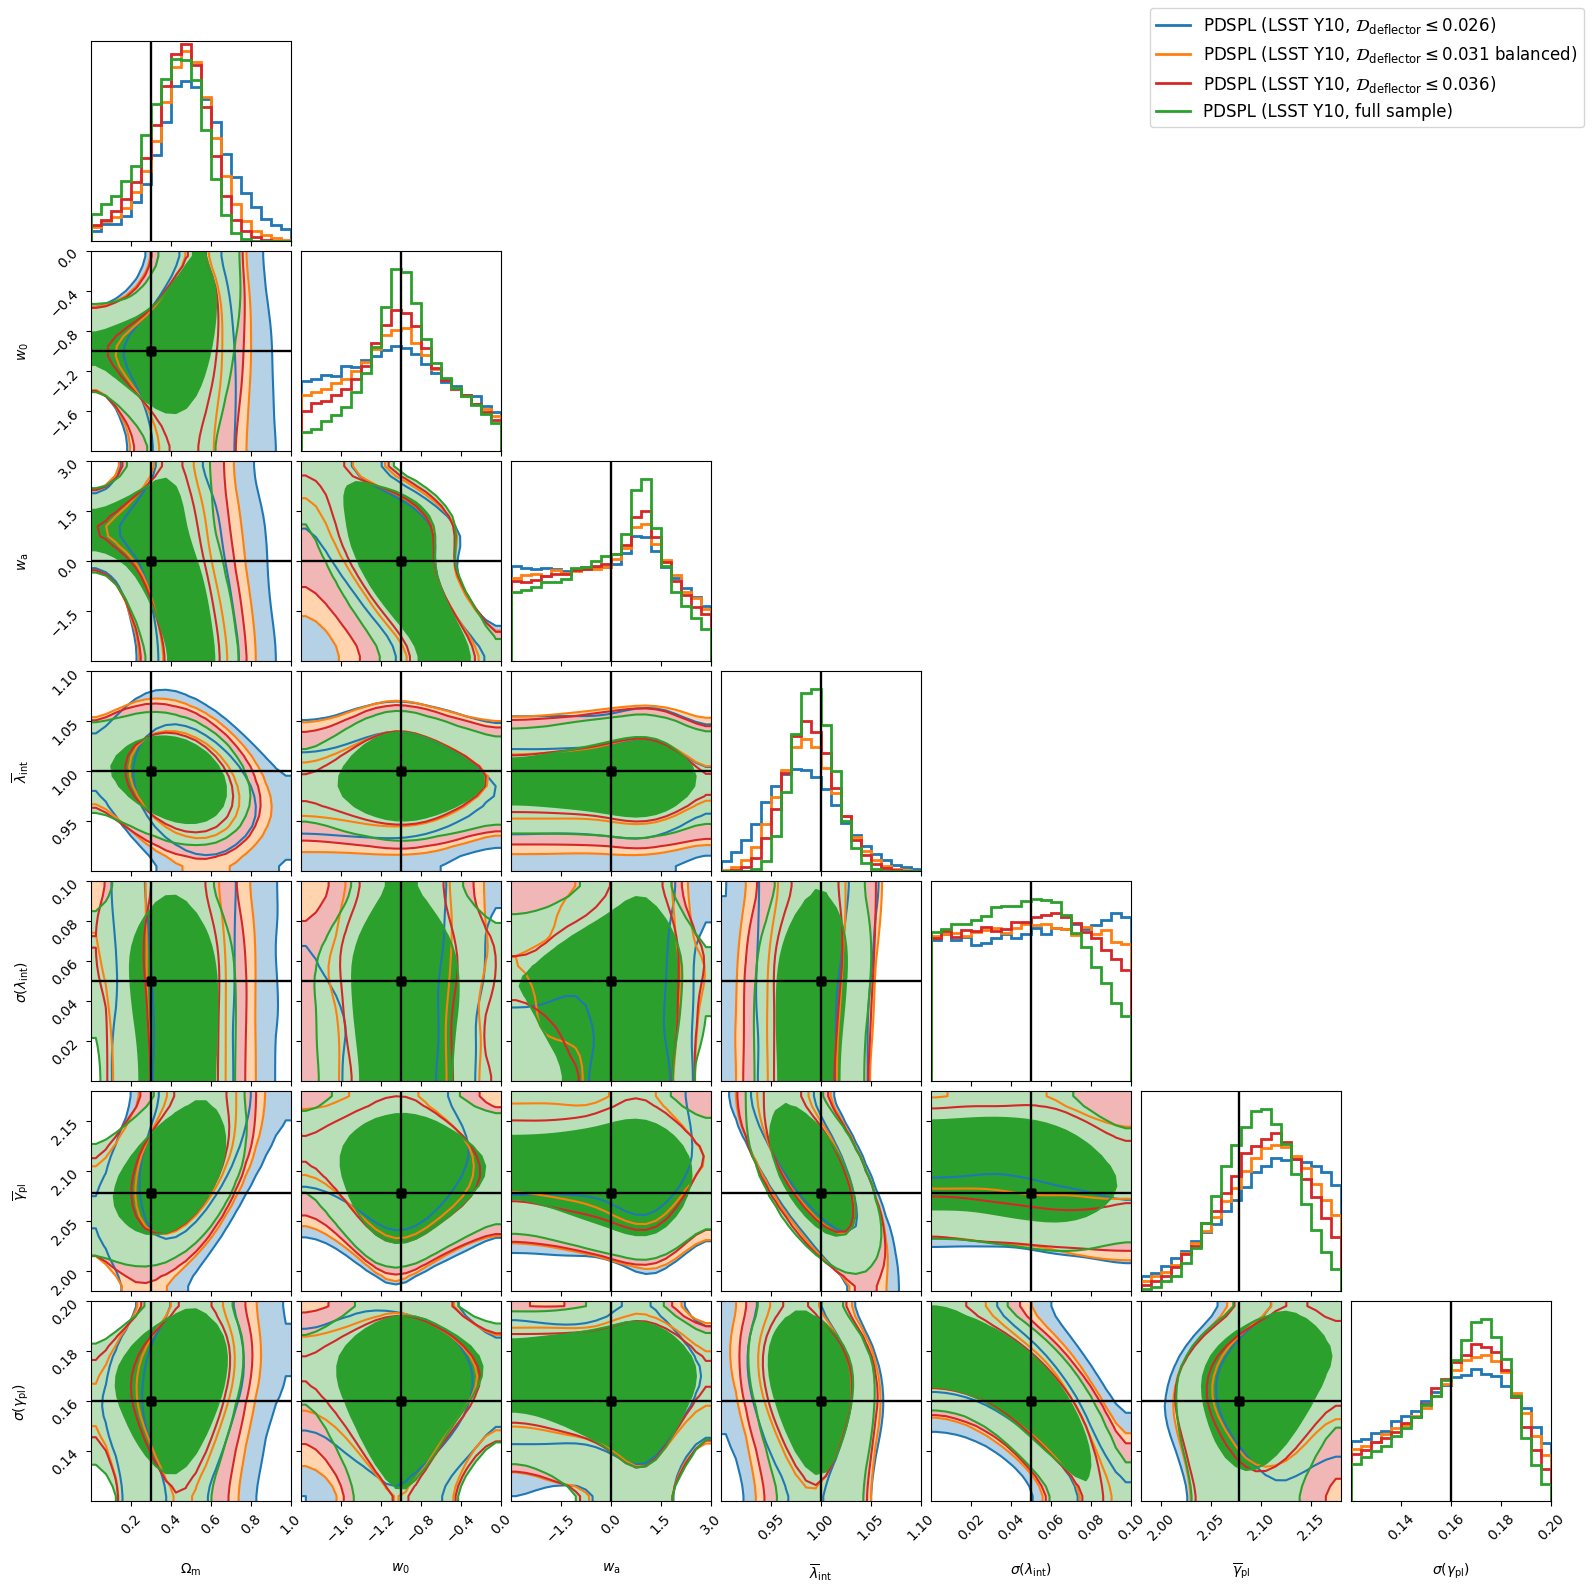

In [8]:
ranges = [(0, 1), (-2, 0), (-3, 3), (0.9, 1.1), (0.0, 0.10), (1.98, 2.18), (0.12, 0.20)]
fig = None
for key, sc in scenarios.items():
    fig = corner.corner(
        sc["samples"], fig=fig, labels=LABELS, range=ranges, color=sc["color"],
        truths=[truth[p] for p in PARAMS], truth_color="k",
        plot_datapoints=False, plot_density=False, fill_contours=True, levels=[0.68, 0.95],
        hist_kwargs={"density": True, "linewidth": 2, "histtype": "step"}, smooth=2,
    )
handles = [plt.Line2D([], [], color=sc["color"], lw=2, label=sc["name"]) for sc in scenarios.values()]
fig.legend(handles=handles, loc="upper right", fontsize=12)
fig.savefig(os.path.join(FIGURE_DIRECTORY, "forecast_w0waCDM_split_v2.png"), dpi=150)
plt.show()

## Loading a shared posterior (example for collaborators)

In [9]:
import emcee
from pandas import DataFrame

backend = emcee.backends.HDFBackend(
    f"{POSTERIOR_DIRECTORY}/{SAMPLE_KEY}_dissim_leq_{split_config['balanced_cut']:.3f}.h5", read_only=True
)
df = DataFrame(backend.get_chain(flat=True, discard=1000, thin=10), columns=LABELS)
df.describe()

,$\Omega_{\rm m}$,$w_0$,$w_{\rm a}$,$\overline{\lambda}_{\rm int}$,$\sigma({\lambda}_{\rm int})$,$\overline{\gamma}_{\rm pl}$,$\sigma({\gamma}_{\rm pl})$
count,89600.000000,89600.000000,89600.000000,89600.000000,89600.000000,89600.000000,89600.000000
mean,0.459477,-1.362030,-0.454419,0.987933,0.058537,2.111865,0.141213
std,0.160362,0.749961,2.376269,0.029210,0.033982,0.052553,0.046775
min,0.000132,-2.999995,-4.999969,0.882455,0.000002,1.857420,0.000010
25%,0.363946,-1.902469,-2.407387,0.967859,0.029582,2.077555,0.118106
50%,0.468032,-1.232244,-0.302002,0.986834,0.057938,2.113532,0.155323
75%,0.564147,-0.804966,1.312115,1.006857,0.086800,2.148038,0.175255
max,0.999347,-0.000016,4.999270,1.165085,0.139295,2.314179,0.231327
